# Práctica 2.5 · Una red neuronal para las fincas cafeteras: regresión y clasificación

Este cuaderno acompaña la clase «Redes neuronales: del perceptrón a la red». Una sola neurona solo dibuja rectas (práctica de temperaturas). Aquí el problema es más rico: el rendimiento y la calidad del café dependen de la altitud, el clima, el suelo y el manejo, y lo hacen de forma **no lineal**. Hay una altitud óptima, el cafetal rinde más a cierta edad y hay factores que se potencian entre sí. Una **red multicapa** puede aprender esas formas; un modelo lineal, no.

Se resuelven dos problemas con los mismos datos:
- **Regresión:** ¿cuántos kilos de café pergamino seco por hectárea producirá la finca? (`rendimiento_kg_ha`)
- **Clasificación:** ¿su café será especial, con 84 puntos o más en la prueba de taza? (`cafe_especial`)

1. Los datos · 2. Preparación y partición · 3. **Regresión**: línea base, red, curvas de aprendizaje y métricas · 4. **Qué aprendió la red** · 5. **Clasificación** · 6. Entrenamiento frente a prueba

**Datos.** `datos/2-5-fincas-cafeteras.xlsx`: 4.000 fincas cafeteras **simuladas con fines didácticos**.

In [1]:
import copy
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, log_loss)
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, suba la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 1. Los datos

In [3]:
fin = pd.read_excel(DATOS / '2-5-fincas-cafeteras.xlsx', sheet_name='fincas')
CAT = ['departamento', 'variedad', 'asistencia_tecnica', 'beneficio']
NUM = [c for c in fin.columns if c not in CAT + ['id_finca', 'rendimiento_kg_ha', 'cafe_especial']]
print(f'{len(fin)} fincas · {len(NUM)} variables numéricas y {len(CAT)} categóricas · faltantes: {fin.isna().sum().sum()}')
print(f'rendimiento: media {fin.rendimiento_kg_ha.mean():,.0f} kg/ha, de {fin.rendimiento_kg_ha.min():,} a {fin.rendimiento_kg_ha.max():,}')
print(f'café especial: {fin.cafe_especial.mean():.1%} de las fincas')
fin.head()

4000 fincas · 12 variables numéricas y 4 categóricas · faltantes: 0
rendimiento: media 1,316 kg/ha, de 3 a 5,402
café especial: 30.6% de las fincas


,id_finca,departamento,altitud_msnm,temperatura_media_c,lluvia_anual_mm,horas_sol_dia,pendiente_pct,ph_suelo,materia_organica_pct,variedad,edad_cafetal_anios,densidad_arboles_ha,sombra_pct,area_ha,fertilizacion_kg_ha,asistencia_tecnica,beneficio,rendimiento_kg_ha,cafe_especial
0,F0001,Risaralda,1211,21.100,2623,5.000,45,6.000,7.400,Geisha,19,4600,35,2.100,995,No,Lavado,400,0
1,F0002,Tolima,1256,19.900,1918,5.400,66,6.000,10.500,Caturra,13,6200,51,10.000,777,No,Lavado,1063,1
2,F0003,Quindío,1711,19.600,1790,5.500,70,5.500,4.800,Castillo,2,5900,48,3.900,1630,No,Natural,1645,1
3,F0004,Nariño,2300,15.800,1677,5.200,6,5.200,7.800,Castillo,9,6300,39,0.700,1761,Sí,Lavado,18,0
4,F0005,Huila,1541,20.000,1239,4.900,68,5.200,7.500,Castillo,12,7100,13,1.900,1068,No,Lavado,1927,0


Hay 4000 fincas, con 12 variables numéricas (altitud, clima, suelo, cafetal, manejo) y 4 categóricas (departamento, variedad, asistencia técnica y beneficio). No hay datos faltantes. Las fincas producen en promedio 1.316 kg/ha, y el 30,6 % tiene café especial.

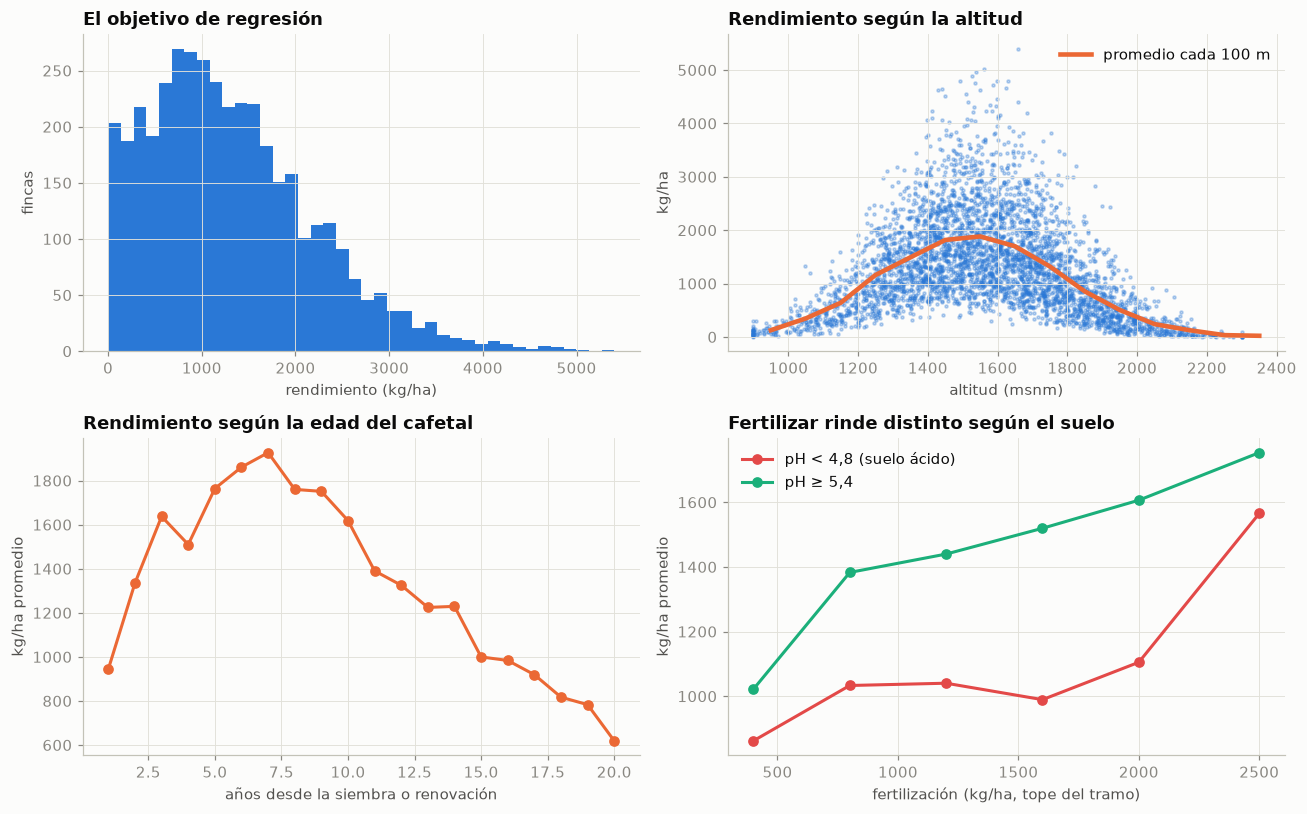

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7.5))
axs[0, 0].hist(fin.rendimiento_kg_ha, bins=40, color=AZUL)
axs[0, 0].set(title='El objetivo de regresión', xlabel='rendimiento (kg/ha)', ylabel='fincas')
axs[0, 1].scatter(fin.altitud_msnm, fin.rendimiento_kg_ha, s=4, alpha=.3, color=AZUL)
g = fin.groupby((fin.altitud_msnm // 100) * 100 + 50).rendimiento_kg_ha.mean()
axs[0, 1].plot(g.index, g.values, color=NARANJA, lw=3, label='promedio cada 100 m')
axs[0, 1].set(title='Rendimiento según la altitud', xlabel='altitud (msnm)', ylabel='kg/ha'); axs[0, 1].legend()
g = fin.groupby('edad_cafetal_anios').rendimiento_kg_ha.mean()
axs[1, 0].plot(g.index, g.values, marker='o', color=NARANJA)
axs[1, 0].set(title='Rendimiento según la edad del cafetal', xlabel='años desde la siembra o renovación', ylabel='kg/ha promedio')
for (lo, hi), col, nom in [((4, 4.8), ROJO, 'pH < 4,8 (suelo ácido)'), ((5.4, 7.1), AQUA, 'pH ≥ 5,4')]:
    d = fin[(fin.ph_suelo >= lo) & (fin.ph_suelo < hi)]
    g = d.groupby(pd.cut(d.fertilizacion_kg_ha, [0, 400, 800, 1200, 1600, 2000, 2500])).rendimiento_kg_ha.mean()
    axs[1, 1].plot([400, 800, 1200, 1600, 2000, 2500], g.values, marker='o', color=col, label=nom)
axs[1, 1].set(title='Fertilizar rinde distinto según el suelo', xlabel='fertilización (kg/ha, tope del tramo)', ylabel='kg/ha promedio'); axs[1, 1].legend()
plt.tight_layout(); plt.show()

Cuatro rasgos que un modelo lineal no puede capturar:

- **Altitud** (arriba a la derecha): el rendimiento sube hasta unos 1.550 m y luego baja. Es una campana, no una recta.
- **Edad del cafetal** (abajo a la izquierda): el mejor año es el 7. Antes el árbol aún no produce del todo y después envejece; por eso se renuevan los cafetales.
- **Fertilización × pH** (abajo a la derecha): en suelos ácidos el fertilizante rinde mucho menos. Es una **interacción**: el efecto de una variable depende de otra.
- El histograma tiene una cola larga a la izquierda: fincas muy bajas, muy altas o recién renovadas que producen poco.

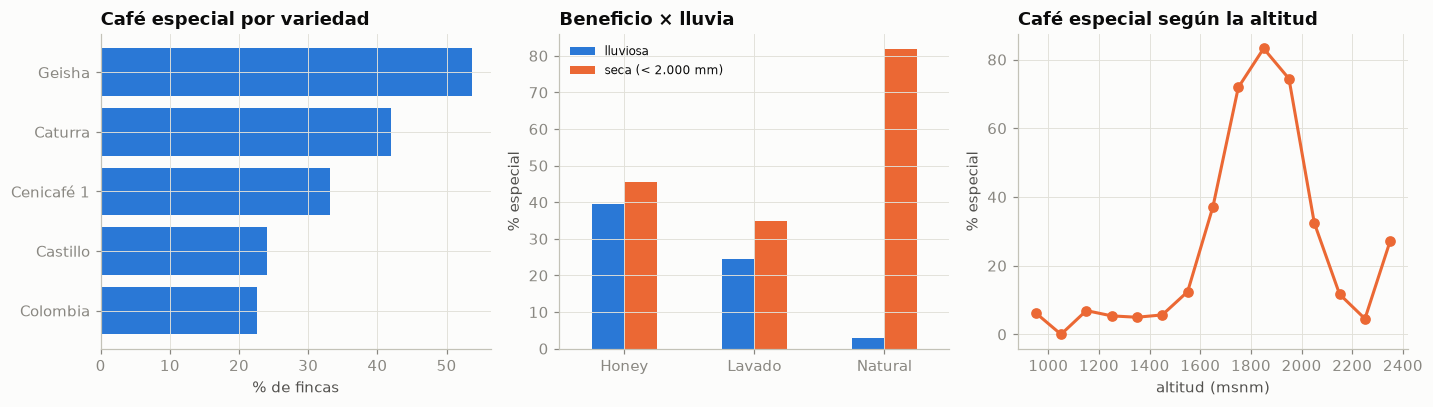

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
g = fin.groupby('variedad').cafe_especial.mean().sort_values()
axs[0].barh(g.index, g.values * 100, color=AZUL); axs[0].set(title='Café especial por variedad', xlabel='% de fincas')
fin['zona_lluvia'] = np.where(fin.lluvia_anual_mm < 2000, 'seca (< 2.000 mm)', 'lluviosa')
g = fin.pivot_table(index='beneficio', columns='zona_lluvia', values='cafe_especial', aggfunc='mean') * 100
g.plot.bar(ax=axs[1], color=[AZUL, NARANJA], rot=0); axs[1].set(title='Beneficio × lluvia', ylabel='% especial', xlabel='')
axs[1].legend(fontsize=8)
g = fin.groupby((fin.altitud_msnm // 100) * 100 + 50).cafe_especial.mean() * 100
axs[2].plot(g.index, g.values, marker='o', color=NARANJA); axs[2].set(title='Café especial según la altitud', xlabel='altitud (msnm)', ylabel='% especial')
fin = fin.drop(columns='zona_lluvia')
plt.tight_layout(); plt.show()

La calidad también es no lineal. La **Geisha** es la variedad con más café especial (54 %). El **beneficio natural** sale muy bien en zonas secas (82 % especial) y muy mal en zonas lluviosas (3 %), otra interacción. La calidad crece con la altitud hasta cierto punto y después cae. Una regresión logística suma efectos y no puede representar bien estas formas.

## 2. Preparación y partición

Una red neuronal necesita números en escalas parecidas. Por eso:
- las **categóricas** se vuelven columnas de 0 y 1 (one-hot);
- las **numéricas** se escalan (media 0 y desviación 1).

Los datos se parten en tres:
- **entrenamiento** (70 %), con el que la red ajusta sus pesos;
- **validación** (15 %), para decidir cuándo parar y qué arquitectura usar;
- **prueba** (15 %), que se usa una sola vez, al final.

El escalador se ajusta solo con el entrenamiento, para no filtrar información de la prueba.

In [6]:
X = fin[CAT + NUM]
idx = np.arange(len(fin))
i_tr, i_tmp = train_test_split(idx, test_size=0.30, random_state=SEMILLA)
i_va, i_te = train_test_split(i_tmp, test_size=0.50, random_state=SEMILLA)
prep = ColumnTransformer([('num', StandardScaler(), NUM), ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)])
Xtr = prep.fit_transform(X.iloc[i_tr]); Xva = prep.transform(X.iloc[i_va]); Xte = prep.transform(X.iloc[i_te])
print(f'entrenamiento {len(i_tr)} · validación {len(i_va)} · prueba {len(i_te)} · columnas después de codificar: {Xtr.shape[1]}')

entrenamiento 2800 · validación 600 · prueba 600 · columnas después de codificar: 32


Quedan 2800 fincas para entrenar, 600 para validar y 600 para probar. Con el one-hot, las 16 variables se vuelven 32 columnas de entrada.

## 3. Regresión: ¿cuánto producirá la finca?

### 3.1 La línea base: regresión lineal

In [7]:
y = fin['rendimiento_kg_ha'].to_numpy(float)
ytr, yva, yte = y[i_tr], y[i_va], y[i_te]
def met_reg(yv, p):
    return {'MAE': mean_absolute_error(yv, p), 'RMSE': mean_squared_error(yv, p) ** 0.5, 'R²': r2_score(yv, p)}
lin = LinearRegression().fit(Xtr, ytr)
base = met_reg(yva, lin.predict(Xva))
print('Regresión lineal en validación:', {k: round(v, 3) for k, v in base.items()})

Regresión lineal en validación: {'MAE': 582.565, 'RMSE': 745.738, 'R²': 0.293}


La regresión lineal se equivoca en 583 kg/ha en promedio (MAE) y explica apenas el 29 % de la variación del rendimiento (R²). No es por falta de datos: es que una suma de rectas no puede dibujar campanas ni interacciones. Esa es la vara que la red debe superar.

### 3.2 La red neuronal, época por época

La red tiene **dos capas ocultas** de 64 y 32 neuronas con activación ReLU y una neurona de salida. Se entrena con Adam, de a lotes de 64 fincas, una época a la vez, y en cada época se mide el error en entrenamiento y en validación. Se guarda la red de la época con **menor error de validación**; si en 30 épocas no mejora, se para (**parada temprana**).

El rendimiento (cientos o miles de kg/ha) también se escala antes de entrenar. Sin eso, la red aprende muy despacio.

In [8]:
MU, SD = ytr.mean(), ytr.std()
def entrenar_red(capas, epocas=400, paciencia=30):
    red = MLPRegressor(hidden_layer_sizes=capas, learning_rate_init=0.002, batch_size=64, random_state=SEMILLA)
    hist, mejor, guardada, ep_mejor, sin_mejora = [], np.inf, None, 0, 0
    for ep in range(epocas):
        red.partial_fit(Xtr, (ytr - MU) / SD)
        rtr = mean_squared_error(ytr, red.predict(Xtr) * SD + MU) ** 0.5
        rva = mean_squared_error(yva, red.predict(Xva) * SD + MU) ** 0.5
        hist.append((rtr, rva))
        if rva < mejor:
            mejor, guardada, ep_mejor, sin_mejora = rva, copy.deepcopy(red), ep, 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    return guardada, np.array(hist), ep_mejor

red, hist, ep_mejor = entrenar_red((64, 32))
pred_red = lambda Xm: red.predict(Xm) * SD + MU
print(f'Se entrenaron {len(hist)} épocas; la mejor fue la {ep_mejor + 1}, con RMSE de validación {hist[ep_mejor, 1]:,.0f} kg/ha')

Se entrenaron 47 épocas; la mejor fue la 17, con RMSE de validación 299 kg/ha


El entrenamiento corrió 47 épocas. La mejor fue la 17, con un RMSE de validación de 299 kg/ha; después no mejoró en 30 épocas seguidas y se detuvo.

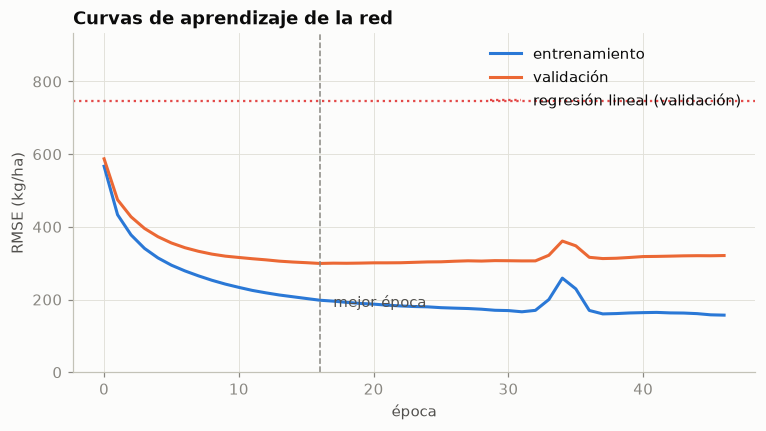

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist[:, 0], color=AZUL, label='entrenamiento')
ax.plot(hist[:, 1], color=NARANJA, label='validación')
ax.axvline(ep_mejor, color=GRIS, ls='--', lw=1); ax.text(ep_mejor + 1, hist[:, 1].min() * 0.6, 'mejor época', color=TINTA2)
ax.axhline(base['RMSE'], color=ROJO, ls=':', lw=1.5, label='regresión lineal (validación)')
ax.set(xlabel='época', ylabel='RMSE (kg/ha)', title='Curvas de aprendizaje de la red', ylim=(0, base['RMSE'] * 1.25)); ax.legend(loc='upper right')
plt.show()

Las dos curvas bajan rápido en las primeras épocas y la red pasa pronto por debajo de la regresión lineal (línea roja, 746 kg/ha). Con el tiempo, la curva de entrenamiento sigue bajando y la de validación se aplana: la red empieza a memorizar el entrenamiento. Por eso se conserva la red de la mejor época de validación y no la última.

### 3.3 ¿Cuántas capas y neuronas?

Se comparan tres arquitecturas en la **validación**; la prueba sigue guardada.

In [10]:
arqs = {}
for capas in [(8,), (64, 32), (128, 64, 32)]:
    if capas == (64, 32):
        r, h, e = red, hist, ep_mejor
    else:
        r, h, e = entrenar_red(capas)
    p = r.predict(Xva) * SD + MU
    arqs[' → '.join(map(str, capas)) + ' → 1'] = {**met_reg(yva, p), 'mejor época': e + 1,
        'pesos': sum(w.size for w in r.coefs_) + sum(b.size for b in r.intercepts_)}
tab_arq = pd.DataFrame(arqs).T
tab_arq.loc['Regresión lineal'] = {**base, 'mejor época': np.nan, 'pesos': Xtr.shape[1] + 1}
tab_arq

,MAE,RMSE,R²,mejor época,pesos
8 → 1,329.455,461.556,0.729,99.000,273.000
64 → 32 → 1,219.601,299.359,0.886,17.000,"4,225.000"
128 → 64 → 32 → 1,209.865,298.277,0.887,31.000,"14,593.000"
Regresión lineal,582.565,745.738,0.293,NaN,33.000


Con una sola capa de 8 neuronas (273 pesos), la red ya alcanza un R² de 0,729, muy por encima del 0,293 de la lineal. La red 64 → 32 (4.225 pesos) llega a 0,886, y la de tres capas (14.593 pesos), a 0,887. Agregar capas y neuronas ayuda, pero cada vez menos, y multiplica los pesos que hay que estimar. Se sigue con la 64 → 32.

### 3.4 Métricas en la prueba

In [11]:
p_lin, p_red = lin.predict(Xte), pred_red(Xte)
tab_reg = pd.DataFrame({'Regresión lineal': met_reg(yte, p_lin), 'Red 64 → 32 → 1': met_reg(yte, p_red)}).T
tab_reg

,MAE,RMSE,R²
Regresión lineal,548.223,709.701,0.282
Red 64 → 32 → 1,224.201,316.638,0.857


En las 600 fincas de prueba, que ningún modelo vio:

- **MAE** (error absoluto medio): la red se equivoca en 224 kg/ha en promedio; la lineal, en 548.
- **RMSE** (raíz del error cuadrático medio, que castiga más los errores grandes): 317 frente a 710 kg/ha.
- **R²**: la red explica el 86 % de la variación del rendimiento; la lineal, el 28 %.

La red reduce el error a menos de la mitad. Las cifras de prueba se parecen a las de validación, así que la elección no fue suerte.

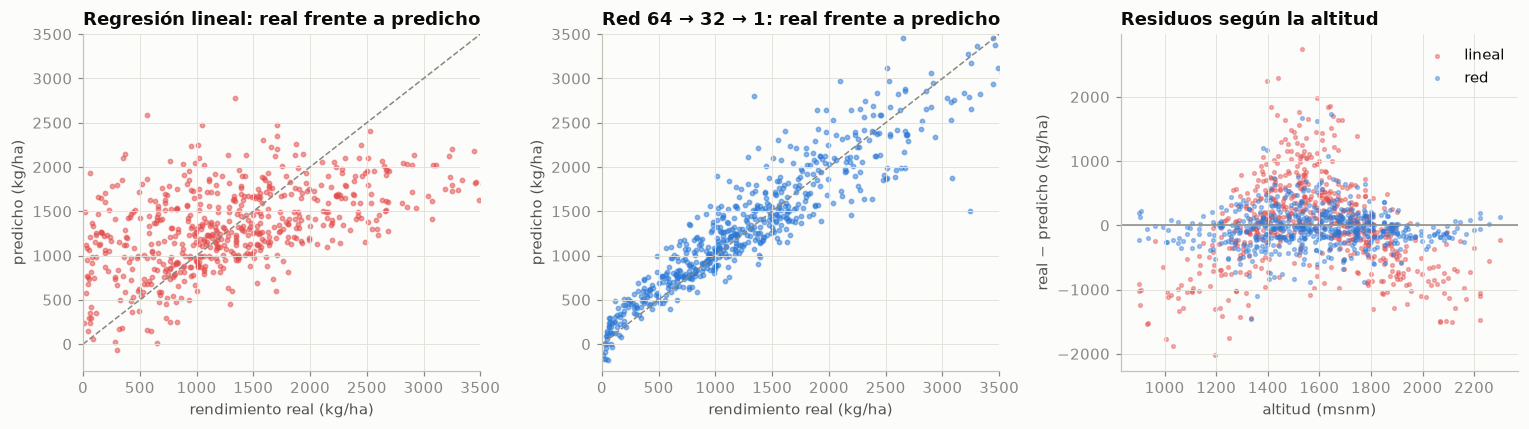

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, p, nom, col in [(axs[0], p_lin, 'Regresión lineal', ROJO), (axs[1], p_red, 'Red 64 → 32 → 1', AZUL)]:
    ax.scatter(yte, p, s=8, alpha=.5, color=col); ax.plot([0, 3500], [0, 3500], color=GRIS, ls='--', lw=1)
    ax.set(title=f'{nom}: real frente a predicho', xlabel='rendimiento real (kg/ha)', ylabel='predicho (kg/ha)', xlim=(0, 3500), ylim=(-300, 3500))
alt = X.iloc[i_te].altitud_msnm
axs[2].scatter(alt, yte - p_lin, s=6, alpha=.4, color=ROJO, label='lineal')
axs[2].scatter(alt, yte - p_red, s=6, alpha=.4, color=AZUL, label='red')
axs[2].axhline(0, color=GRIS, lw=1); axs[2].set(title='Residuos según la altitud', xlabel='altitud (msnm)', ylabel='real − predicho (kg/ha)'); axs[2].legend()
plt.tight_layout(); plt.show()

En el panel izquierdo, la regresión lineal deja una nube ancha: a las fincas que producen mucho les predice poco, y a las que producen poco les predice de más (incluso valores negativos). La red (centro) se pega a la diagonal. A la derecha están los residuos según la altitud. Los de la lineal tienen forma de **U invertida**: subestima en las altitudes medias y sobreestima en los extremos, porque una recta no puede dibujar la campana de la altitud. Los de la red quedan alrededor de cero en todas las altitudes.

## 4. Qué aprendió la red

Una red no da coeficientes que se lean directamente. Para entenderla se usan dos herramientas:
- **Dependencia parcial**: se fija una variable en un valor para todas las fincas y se promedia lo que predice el modelo. Repetido para varios valores, muestra cómo responde el modelo a esa variable.
- **Importancia por permutación**: se barajan los valores de una variable en la prueba y se mide cuánto empeora el error. Si empeora mucho, la variable importa.

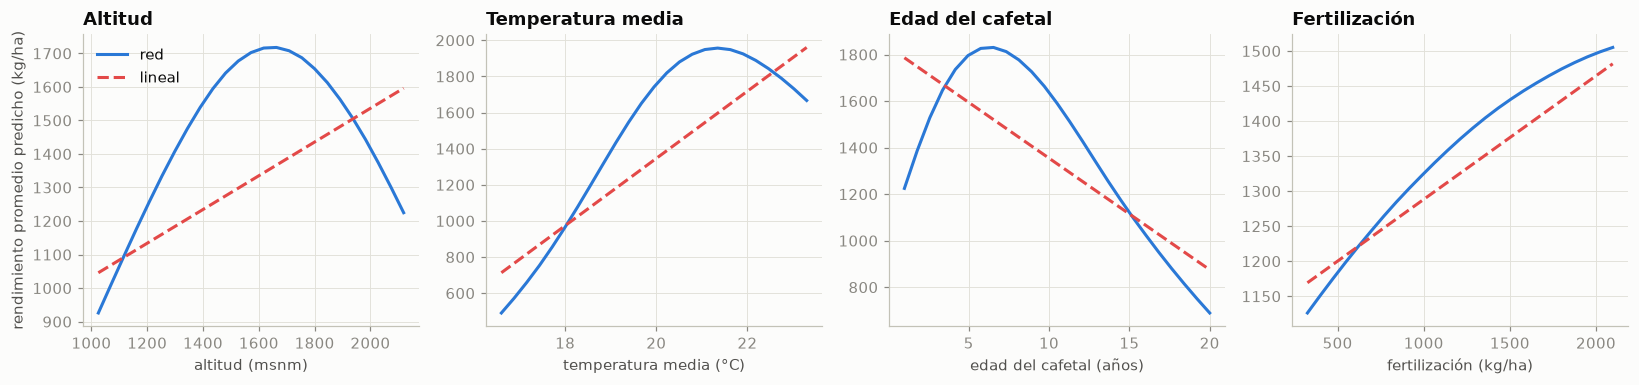

In [13]:
pred_lin_df = lambda d: lin.predict(prep.transform(d))
pred_red_df = lambda d: pred_red(prep.transform(d))
muestra = X.iloc[i_te]
def dependencia(pred, col, grid):
    out = []
    for v in grid:
        d = muestra.copy(); d[col] = v; out.append(pred(d).mean())
    return np.array(out)
VARS = [('altitud_msnm', 'altitud (msnm)'), ('temperatura_media_c', 'temperatura media (°C)'),
        ('edad_cafetal_anios', 'edad del cafetal (años)'), ('fertilizacion_kg_ha', 'fertilización (kg/ha)')]
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (col, nom) in zip(axs, VARS):
    grid = np.linspace(X[col].quantile(.02), X[col].quantile(.98), 25)
    ax.plot(grid, dependencia(pred_red_df, col, grid), color=AZUL, label='red')
    ax.plot(grid, dependencia(pred_lin_df, col, grid), color=ROJO, ls='--', label='lineal')
    ax.set(xlabel=nom, title=nom.split(' (')[0].capitalize())
axs[0].set_ylabel('rendimiento promedio predicho (kg/ha)'); axs[0].legend()
plt.tight_layout(); plt.show()

La red (azul) descubrió sola las formas que se vieron en la exploración: una **altitud** y una **temperatura** óptimas, con caída a los dos lados; la **edad** con su pico en los primeros años y un descenso lento después, y la **fertilización** con rendimientos decrecientes: cada kilo adicional aporta menos. La regresión lineal (rojo) solo puede trazar rectas: para la altitud y la temperatura dice «mientras más, mejor» y no ve la caída después del óptimo; para la edad dice «mientras más joven, mejor» y se pierde el arranque de los primeros años.

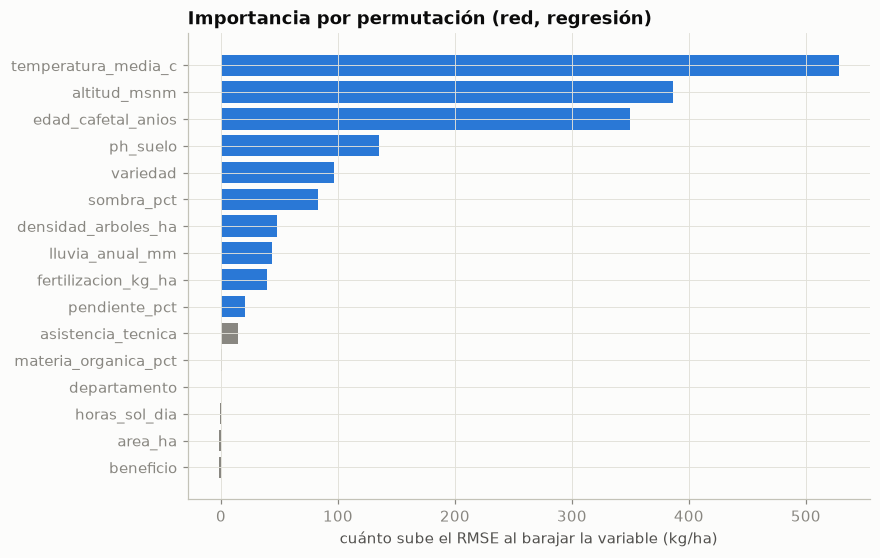

In [14]:
rng = np.random.default_rng(SEMILLA)
rmse0 = mean_squared_error(yte, pred_red_df(muestra)) ** 0.5
imp = {}
for col in CAT + NUM:
    deltas = []
    for _ in range(5):
        d = muestra.copy(); d[col] = rng.permutation(d[col].to_numpy())
        deltas.append(mean_squared_error(yte, pred_red_df(d)) ** 0.5 - rmse0)
    imp[col] = np.mean(deltas)
imp = pd.Series(imp).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(imp.index, imp.values, color=[GRIS if v < 15 else AZUL for v in imp.values])
ax.set(title='Importancia por permutación (red, regresión)', xlabel='cuánto sube el RMSE al barajar la variable (kg/ha)')
plt.show()

Las variables que más pesan son temperatura_media_c (al barajarla, el RMSE sube 528 kg/ha), altitud_msnm (387) y edad_cafetal_anios (350). Al otro extremo, **area_ha** (−1) y **horas_sol_dia** (−1) casi no cuentan, igual que el beneficio. Es lo esperado: en la simulación no influyen en el rendimiento (el beneficio solo afecta la calidad). El departamento tampoco suma, porque lo que importa de él ya está en la altitud y la lluvia. La red no se dejó engañar por variables que solo aportan ruido.

## 5. Clasificación: ¿será café especial?

La partición se hace otra vez, ahora **estratificada**, para que entrenamiento, validación y prueba tengan la misma proporción de cafés especiales.

In [15]:
ye = fin['cafe_especial'].to_numpy()
j_tr, j_tmp = train_test_split(idx, test_size=0.30, random_state=SEMILLA, stratify=ye)
j_va, j_te = train_test_split(j_tmp, test_size=0.50, random_state=SEMILLA, stratify=ye[j_tmp])
prep_c = ColumnTransformer([('num', StandardScaler(), NUM), ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)])
Ctr = prep_c.fit_transform(X.iloc[j_tr]); Cva = prep_c.transform(X.iloc[j_va]); Cte = prep_c.transform(X.iloc[j_te])
etr, eva, ete = ye[j_tr], ye[j_va], ye[j_te]

logi = LogisticRegression(max_iter=2000).fit(Ctr, etr)

clf = MLPClassifier(hidden_layer_sizes=(64, 32), learning_rate_init=0.002, batch_size=64, random_state=SEMILLA)
hist_c, mejor, guardada, ep_c, sin = [], np.inf, None, 0, 0
for ep in range(400):
    clf.partial_fit(Ctr, etr, classes=[0, 1])
    ltr, lva = log_loss(etr, clf.predict_proba(Ctr)[:, 1]), log_loss(eva, clf.predict_proba(Cva)[:, 1])
    hist_c.append((ltr, lva))
    if lva < mejor:
        mejor, guardada, ep_c, sin = lva, copy.deepcopy(clf), ep, 0
    else:
        sin += 1
        if sin >= 30:
            break
clf, hist_c = guardada, np.array(hist_c)
print(f'{etr.mean():.1%} de especiales en entrenamiento, {eva.mean():.1%} en validación, {ete.mean():.1%} en prueba')
print(f'Red: {len(hist_c)} épocas; la mejor fue la {ep_c + 1}, con pérdida logarítmica de validación {hist_c[ep_c, 1]:.3f}')
print(f'Regresión logística: pérdida logarítmica de validación {log_loss(eva, logi.predict_proba(Cva)[:, 1]):.3f}')

30.6% de especiales en entrenamiento, 30.7% en validación, 30.5% en prueba
Red: 39 épocas; la mejor fue la 9, con pérdida logarítmica de validación 0.361
Regresión logística: pérdida logarítmica de validación 0.479


La red de clasificación tiene la misma arquitectura (64 → 32), pero su neurona de salida usa la **sigmoide**: devuelve la probabilidad de que el café sea especial. Se entrena con la **pérdida logarítmica** (log loss), que castiga sobre todo a un modelo seguro que se equivoca. La mejor época fue la 9, con una pérdida de validación de 0,361; la regresión logística llega a 0,479.

In [16]:
def met_clf(yv, p, u=0.5):
    h = (p >= u).astype(int)
    return {'exactitud': accuracy_score(yv, h), 'precisión': precision_score(yv, h), 'sensibilidad': recall_score(yv, h),
            'F1': f1_score(yv, h), 'AUC': roc_auc_score(yv, p)}
q_log, q_red = logi.predict_proba(Cte)[:, 1], clf.predict_proba(Cte)[:, 1]
tab_clf = pd.DataFrame({'Regresión logística': met_clf(ete, q_log), 'Red 64 → 32 → 1': met_clf(ete, q_red)}).T
tab_clf

,exactitud,precisión,sensibilidad,F1,AUC
Regresión logística,0.795,0.692,0.590,0.637,0.863
Red 64 → 32 → 1,0.845,0.716,0.814,0.762,0.921


Con umbral 0,5, en las 600 fincas de prueba:

- **Exactitud** (de cada 100 fincas, cuántas clasifica bien): 84,5 % la red y 79,5 % la logística. Ojo: como solo el 30 % es especial, decir siempre «no especial» ya acierta el 70 %.
- **Precisión** (de las que marca como especiales, cuántas lo son): 72 % frente a 69 %.
- **Sensibilidad** (de las especiales, cuántas encuentra): 81 % frente a 59 %.
- **F1** (equilibrio entre las dos anteriores): 0,76 frente a 0,64.
- **AUC** (área bajo la curva ROC: la probabilidad de que una finca especial reciba un puntaje mayor que una que no lo es): 0,921 frente a 0,863.

La red gana en todas las métricas.

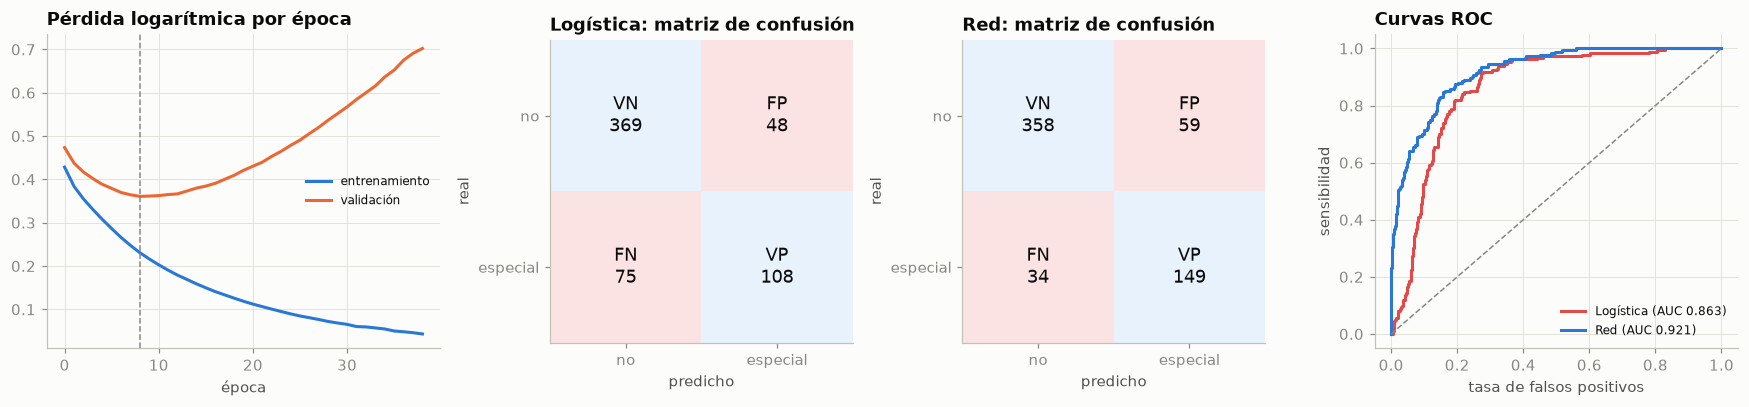

In [17]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), gridspec_kw={'width_ratios': [1.3, 1, 1, 1.2]})
axs[0].plot(hist_c[:, 0], color=AZUL, label='entrenamiento'); axs[0].plot(hist_c[:, 1], color=NARANJA, label='validación')
axs[0].axvline(ep_c, color=GRIS, ls='--', lw=1); axs[0].set(title='Pérdida logarítmica por época', xlabel='época'); axs[0].legend(fontsize=8)
for ax, q, nom in [(axs[1], q_log, 'Logística'), (axs[2], q_red, 'Red')]:
    m = confusion_matrix(ete, (q >= .5).astype(int))
    ax.imshow([[0, 1], [1, 0]], cmap=LinearSegmentedColormap.from_list('mc', ['#e8f2fc', '#fbe3e3']), vmin=0, vmax=1)
    for (i, j), r in zip([(0, 0), (0, 1), (1, 0), (1, 1)], ['VN', 'FP', 'FN', 'VP']):
        ax.text(j, i, f'{r}\n{m[i, j]}', ha='center', va='center', fontsize=12, color=TINTA)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['no', 'especial'], yticklabels=['no', 'especial'], xlabel='predicho', ylabel='real', title=f'{nom}: matriz de confusión')
    ax.grid(False)
for q, nom, col in [(q_log, 'Logística', ROJO), (q_red, 'Red', AZUL)]:
    fpr, tpr, _ = roc_curve(ete, q); axs[3].plot(fpr, tpr, color=col, label=f'{nom} (AUC {roc_auc_score(ete, q):.3f})')
axs[3].plot([0, 1], [0, 1], color=GRIS, ls='--', lw=1)
axs[3].set(title='Curvas ROC', xlabel='tasa de falsos positivos', ylabel='sensibilidad'); axs[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

A la izquierda, la pérdida de validación toca su mínimo en la época 9 y después **sube**, mientras la de entrenamiento sigue bajando: es el sobreajuste en vivo. Por eso se guarda la red de la mejor época. En las matrices de confusión, VP son los cafés especiales bien detectados, FN los especiales que se escaparon, FP las falsas alarmas y VN los no especiales bien descartados. La red detecta 149 especiales y deja escapar 34; la logística detecta 108 y deja escapar 75. En las curvas ROC, la de la red queda por encima en casi todo el recorrido: para cualquier tasa de falsas alarmas que se tolere, encuentra más cafés especiales.

## 6. Entrenamiento frente a prueba

Un modelo que memoriza el entrenamiento funciona mal con datos nuevos. Se comparan las métricas en las dos partes.

In [18]:
comp = pd.DataFrame({
    ('Regresión', 'R² lineal'): [r2_score(ytr, lin.predict(Xtr)), r2_score(yte, p_lin)],
    ('Regresión', 'R² red'): [r2_score(ytr, pred_red(Xtr)), r2_score(yte, p_red)],
    ('Clasificación', 'AUC logística'): [roc_auc_score(etr, logi.predict_proba(Ctr)[:, 1]), roc_auc_score(ete, q_log)],
    ('Clasificación', 'AUC red'): [roc_auc_score(etr, clf.predict_proba(Ctr)[:, 1]), roc_auc_score(ete, q_red)]},
    index=['entrenamiento', 'prueba'])
comp

Regresión        Clasificación        
              R² lineal R² red AUC logística AUC red
entrenamiento     0.305  0.950         0.872   0.966
prueba            0.282  0.857         0.863   0.921

La red rinde mejor en entrenamiento que en prueba: R² 0,950 frente a 0,857, y AUC 0,966 frente a 0,921. Esa brecha es la señal de que la red ya empezó a ajustarse a particularidades del entrenamiento. La parada temprana la contiene, y los retos proponen reducirla con regularización. Los modelos lineales casi no tienen brecha (R² 0,305 frente a 0,282), pero tampoco aprenden la forma de los datos. Aun en la prueba, la red supera con holgura a la línea base.

## Conclusiones

1. Cuando la relación es **no lineal** (óptimos, picos, interacciones), una red con capas ocultas supera claramente a los modelos lineales. En la regresión, el R² de prueba pasa de 0,28 a 0,86 y el MAE baja de 548 a 224 kg/ha. En la clasificación, el AUC sube de 0,863 a 0,921 y el F1, de 0,64 a 0,76.
2. La red necesita **preparación**: categóricas en one-hot, entradas escaladas y, en la regresión, también el objetivo escalado.
3. Las **curvas de aprendizaje** con validación muestran cuándo parar: después de la mejor época, la red empieza a memorizar.
4. Más capas ayudan cada vez menos y multiplican los pesos. La arquitectura se elige con la validación, nunca con la prueba.
5. Una red no se lee como una regresión, pero la **dependencia parcial** y la **importancia por permutación** muestran qué aprendió: recuperó las campanas de altitud y temperatura y descartó las variables sin efecto.
6. Siempre hay que compararla con una **línea base**. Si la red no le gana a la regresión lineal o logística, no vale la pena su complejidad.

## Retos

1. Entrene la red de regresión **sin escalar el objetivo** y compare las curvas de aprendizaje.
2. Pruebe otras activaciones (`activation='tanh'`) y otras tasas de aprendizaje. ¿Cambia la mejor época?
3. Agregue regularización (`alpha=0.01`, la penalización L2 de scikit-learn) y mire si se cierra la brecha entre entrenamiento y prueba.
4. Compare la red con un random forest o un gradient boosting (clases 2.2). ¿Gana siempre la red en datos de tabla?
5. Cambie el umbral de la clasificación a 0,3. ¿Qué gana y qué pierde un comprador que busca no dejar escapar ningún café especial?
6. Con Keras, construya la misma red (`Dense(64, 'relu')`, `Dense(32, 'relu')`, `Dense(1)`) con `EarlyStopping` y compare las métricas.